In [2]:
from pathlib import Path

PROJECT_DIR = Path("/Users/salman/Projects/AI/WoundVision-AI")

print("=== MODEL CHECKPOINTS ===")
for file in (PROJECT_DIR / "models").glob("*.pth"):
    print(file.name)

print("\n=== PYTHON SCRIPTS ===")
for file in (PROJECT_DIR / "scripts").glob("*.py"):
    print(file.name)

print("\n=== TRAINING RUNS ===")
for folder in sorted((PROJECT_DIR / "runs").iterdir()):
    if folder.is_dir():
        print(folder.name)

=== MODEL CHECKPOINTS ===
woundvision_v02_78189535.pth
woundvision_mvp_3d6d1c55.pth

=== PYTHON SCRIPTS ===
download_dataset.py
check_saved_checkpoint.py
check_training.py
check_dataset.py
check_evaluation.py
compare_checkpoints.py
check_model.py
run_training.py
visualize_predictions.py

=== TRAINING RUNS ===
20261121_130312_556aeb
20261121_130732_b057bc
20261121_131546_bbbf18
20261121_132717_22f682
20261121_134605_bdef60
20261121_161303_016b26
20261121_161718_2b50d2
20261121_161941_71432a
20261121_162352_da4143
20261121_184858_8e42d7
20261121_185427_e291f3
visualizations


In [3]:
print("=== TRAINING FILES ===")

for run_dir in sorted((PROJECT_DIR / "runs").iterdir()):
    if not run_dir.is_dir():
        continue

    print(f"\n{run_dir.name}")

    for file in sorted(run_dir.iterdir()):
        print(" -", file.name)

print("\n=== SOURCE CODE ===")

for file in sorted((PROJECT_DIR / "src").rglob("*.py")):
    print(file.relative_to(PROJECT_DIR))

=== TRAINING FILES ===

20261121_130312_556aeb
 - config.json
 - metrics.jsonl

20261121_130732_b057bc
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_131546_bbbf18
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_132717_22f682
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_134605_bdef60
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_161303_016b26
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_161718_2b50d2
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_161941_71432a
 - config.json
 - metrics.jsonl

20261121_162352_da4143
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_184858_8e42d7
 - best_model.pth
 - config.json
 - metrics.jsonl

20261121_185427_e291f3
 - best_model.pth
 - config.json
 - metrics.jsonl

visualizations
 - necrotic_overlay.png
 - v02_vs_v03.png

=== SOURCE CODE ===
src/woundvision/__init__.py
src/woundvision/config.py
src/woundvision/data.py
src/woundvision/evaluate.py
src/woundvisio

In [5]:
import json

run_dir = PROJECT_DIR / "runs" / "20261121_185427_e291f3"

# Membaca konfigurasi eksperimen
with open(run_dir / "config.json", "r") as f:
    config = json.load(f)

print("=== CONFIGURATION ====")
print(json.dumps(config, indent=2))

# Membaca catatan metrik training
with open(run_dir / "metrics.jsonl", "r") as f:
    metrics = [json.loads(line) for line in f if line.strip()]

print("\n=== TOTAL RECORDS ===")
print(len(metrics))

print("\n=== LAST METRIC ===")
print(json.dumps(metrics[-1], indent=2))

print("\n=== CHECKPOINT ===")
print((run_dir / "best_model.pth").exists())

=== CONFIGURATION ====
{
  "run_id": "20261121_185427_e291f3",
  "seed": 42,
  "epochs": 3,
  "batch_size": 2,
  "train_images": 111,
  "validation_images": 30,
  "starting_checkpoint": "woundvision_v02_78189535.pth",
  "class_weights": [
    0.25,
    1.0,
    1.3412,
    1.0135,
    6.0,
    1.0
  ],
  "checkpoint_metric": "clinical_3_dice",
  "device": "cpu"
}

=== TOTAL RECORDS ===
3

=== LAST METRIC ===
{
  "epoch": 3,
  "train_loss": 0.7363627526376929,
  "macro_tissue_dice": 0.3741759955883026,
  "wound_dice": 0.7719025015830994,
  "clinical_3_dice": 0.5118480225404104,
  "pixel_accuracy": 0.8845764994621277,
  "dice_per_class": {
    "Background": 0.9566969275474548,
    "Epithelial": 0.3353358805179596,
    "Slough": 0.34546852111816406,
    "Granulation": 0.7052131295204163,
    "Necrotic": 0.48486241698265076,
    "Other": 0.0
  }
}

=== CHECKPOINT ===
True


In [6]:
print("=== METRIC KEYS ===")
print(list(metrics[-1].keys()))

print("\n=== EPOCH SUMMARY ===")

for i, record in enumerate(metrics, start=1):
    scalar_metrics = {
        key: round(value, 4)
        if isinstance(value, float) else value
        for key, value in record.items()
        if isinstance(value, (int, float))
    }

    print(f"Record {i}: {scalar_metrics}")

print("\n=== NESTED METRICS ===")

for key, value in metrics[-1].items():
    if isinstance(value, dict):
        print(f"{key}: {list(value.keys())}")

=== METRIC KEYS ===
['epoch', 'train_loss', 'macro_tissue_dice', 'wound_dice', 'clinical_3_dice', 'pixel_accuracy', 'dice_per_class']

=== EPOCH SUMMARY ===
Record 1: {'epoch': 1, 'train_loss': 0.8336, 'macro_tissue_dice': 0.2356, 'wound_dice': 0.7649, 'clinical_3_dice': 0.276, 'pixel_accuracy': 0.8639}
Record 2: {'epoch': 2, 'train_loss': 0.7844, 'macro_tissue_dice': 0.2917, 'wound_dice': 0.7623, 'clinical_3_dice': 0.3861, 'pixel_accuracy': 0.8885}
Record 3: {'epoch': 3, 'train_loss': 0.7364, 'macro_tissue_dice': 0.3742, 'wound_dice': 0.7719, 'clinical_3_dice': 0.5118, 'pixel_accuracy': 0.8846}

=== NESTED METRICS ===
dice_per_class: ['Background', 'Epithelial', 'Slough', 'Granulation', 'Necrotic', 'Other']


In [7]:
classes = ["Granulation", "Slough", "Necrotic"]

for record in metrics:
    print(f"\n=== EPOCH {record['epoch']} ===")

    for tissue in classes:
        dice = record["dice_per_class"][tissue]
        print(f"{tissue}: {dice:.4f}")


=== EPOCH 1 ===
Granulation: 0.6076
Slough: 0.1873
Necrotic: 0.0333

=== EPOCH 2 ===
Granulation: 0.6563
Slough: 0.3435
Necrotic: 0.1586

=== EPOCH 3 ===
Granulation: 0.7052
Slough: 0.3455
Necrotic: 0.4849


In [8]:
runs_summary = []

for run_dir in sorted((PROJECT_DIR / "runs").iterdir()):

    config_file = run_dir / "config.json"
    metrics_file = run_dir / "metrics.jsonl"
    checkpoint_file = run_dir / "best_model.pth"

    if not all([
        config_file.exists(),
        metrics_file.exists(),
        checkpoint_file.exists()
    ]):
        continue

    with open(config_file) as f:
        config = json.load(f)

    with open(metrics_file) as f:
        records = [
            json.loads(line)
            for line in f if line.strip()
        ]

    valid_records = [
        r for r in records
        if isinstance(r.get("clinical_3_dice"), (int, float))
    ]

    if not valid_records:
        continue

    best = max(
        valid_records,
        key=lambda r: r["clinical_3_dice"]
    )

    runs_summary.append({
        "run": run_dir.name,
        "monitor": config.get("checkpoint_metric", "unknown"),
        "epoch": best["epoch"],
        "clinical_3_dice": best["clinical_3_dice"],
        "necrotic_dice": best["dice_per_class"]["Necrotic"]
    })

for run in sorted(
    runs_summary,
    key=lambda x: x["clinical_3_dice"],
    reverse=True
):
    print(run)

{'run': '20261121_185427_e291f3', 'monitor': 'clinical_3_dice', 'epoch': 3, 'clinical_3_dice': 0.5118480225404104, 'necrotic_dice': 0.48486241698265076}
{'run': '20261121_162352_da4143', 'monitor': 'clinical_3_dice', 'epoch': 3, 'clinical_3_dice': 0.4276338418324788, 'necrotic_dice': 0.20392706990242004}
{'run': '20261121_184858_8e42d7', 'monitor': 'clinical_3_dice', 'epoch': 2, 'clinical_3_dice': 0.37529245018959045, 'necrotic_dice': 0.036554157733917236}
{'run': '20261121_161718_2b50d2', 'monitor': 'clinical_3_dice', 'epoch': 1, 'clinical_3_dice': 0.3600494023412466, 'necrotic_dice': 0.012663500383496284}
{'run': '20261121_134605_bdef60', 'monitor': 'unknown', 'epoch': 1, 'clinical_3_dice': 0.35732137008259696, 'necrotic_dice': 0.00997828971594572}
{'run': '20261121_161303_016b26', 'monitor': 'unknown', 'epoch': 1, 'clinical_3_dice': 0.35732137008259696, 'necrotic_dice': 0.00997828971594572}


In [9]:
import torch

best_run = "20261121_185427_e291f3"

checkpoint_path = (
    PROJECT_DIR / "runs" / best_run / "best_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("=== CHECKPOINT INFORMATION ===")
print("File:", checkpoint_path.name)
print("Type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Keys:", list(checkpoint.keys())[:20])

    for key in ["epoch", "best_metric", "clinical_3_dice"]:
        if key in checkpoint:
            print(f"{key}:", checkpoint[key])

=== CHECKPOINT INFORMATION ===
File: best_model.pth
Type: dict
Keys: ['model_state', 'optimizer_state', 'epoch', 'seed', 'macro_tissue_dice', 'wound_dice', 'dice_per_class', 'train_images', 'clinical_3_dice', 'starting_checkpoint']
epoch: 3
clinical_3_dice: 0.5118480225404104


In [10]:
import ast

model_path = PROJECT_DIR / "src/woundvision/model.py"

source = model_path.read_text(encoding="utf-8")
tree = ast.parse(source)

print("=== MODEL ARCHITECTURE ===")

for node in tree.body:
    if isinstance(node, ast.ClassDef):
        print("\nClass:", node.name)

        for method in node.body:
            if isinstance(method, ast.FunctionDef):
                if method.name == "__init__":
                    print("Constructor:", ast.unparse(method.args))

    elif isinstance(node, ast.FunctionDef):
        print("\nFunction:", node.name)
        print("Arguments:", ast.unparse(node.args))

=== MODEL ARCHITECTURE ===

Function: build_model
Arguments: 


In [11]:
print("=== IMPORTS ===")

for node in tree.body:
    if isinstance(node, (ast.Import, ast.ImportFrom)):
        print(ast.get_source_segment(source, node))

print("\n=== BUILD MODEL ===")

for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        if node.name == "build_model":
            print(ast.get_source_segment(source, node))

=== IMPORTS ===
import segmentation_models_pytorch as smp

=== BUILD MODEL ===
def build_model():
    """
    Build WoundVision AI U-Net ResNet34.
    Output:
        6 Segmentation classes.
    """
    
    model = smp.Unet(
        encoder_name="resnet34",
        encode_weights=None,
        in_channels=3,
        classes=6,
        activation=None
    )

    return model


In [13]:
%pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 875.2 kB/s  0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 788.0 kB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 2.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [segmentation-models-pytorch]on-models-pytorch]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import segmentation_models_pytorch as smp
import inspect

print("SMP Version:", smp.__version__)
print("Encoder weights supported:",
      "encoder_weights" in inspect.signature(smp.Unet).parameters)

SMP Version: 0.6.0
Encoder weights supported: True


/Users/salman/Projects/AI/WoundVision-AI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
from pathlib import Path
import torch
import segmentation_models_pytorch as smp

# Tentukan Device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Bangun arsitektur U-Net
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
)

# Tentukan lokasi checkpoint
checkpoint_path = (
    Path("/Users/salman/Projects/AI/WoundVision-AI")
    / "runs"
    / "20261121_185427_e291f3"
    / "best_model.pth"
)

# Baca checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Masukkan bobot ke model
model.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

# Pindahkan model ke GPU dan aktifkan mode evaluasi
model = model.to(device)
model.eval()

print("Device:", device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Clinical-3 Dice:", round(checkpoint["clinical_3_dice"], 4))
print("Model ready!")



Device: mps
Checkpoint epoch: 3
Clinical-3 Dice: 0.5118
Model ready!


In [17]:
import ast

data_path = PROJECT_DIR / "src/woundvision/data.py"

source = data_path.read_text(encoding="utf-8")
tree = ast.parse(source)

print("=== DATA PIPELINE ===")

for node in tree.body:
    if isinstance(node, ast.ClassDef):
        print("Class:", node.name)

        for method in node.body:
            if isinstance(method, ast.FunctionDef):
                print(" Method:", method.name)

    elif isinstance(node, ast.FunctionDef):
        print("Function:", node.name)

print("\n=== DATASET FOLDERS ===")

for item in sorted((PROJECT_DIR / "data").iterdir()):
    print(item.name)

=== DATA PIPELINE ===
Class: WoundDataset
 Method: __init__
 Method: __len__
 Method: __getitem__

=== DATASET FOLDERS ===
LUTSeg


In [18]:
import ast

data_path = PROJECT_DIR / "src/woundvision/data.py"

source = data_path.read_text(encoding="utf-8")
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.ClassDef):
        if node.name == "WoundDataset":

            for method in node.body:
                if isinstance(method, ast.FunctionDef):
                    if method.name in ["__init__", "__getitem__"]:

                        print(f"\n=== {method.name} ===")
                        print(ast.get_source_segment(source, method))


=== __init__ ===
def __init__(self, root_dir, split_file, image_size=320):
        self.root_dir = Path(root_dir)
        self.image_size = image_size
        self.samples = []

        # Baca daftar pasangan gambar dan mask
        lines = (
            (self.root_dir / split_file)
            .read_text(encoding="utf-8")
            .splitlines()
        )

        for line in lines:
            
            if not line.strip():
                continue

            parts = line.strip().split()

            if len(parts) != 2:
                raise ValueError(
                    f"Invalid dataset entry: {line}"
                )

            image_path, mask_path = parts

            self.samples.append((
                self.root_dir / image_path,
                self.root_dir / mask_path
            ))

=== __getitem__ ===
def __getitem__(self, index):
        image_path, mask_path = self.samples[index]

        # Baca gambar RGB
        with Image.open(image_path) as img:
      

In [20]:
lutseg_dir = PROJECT_DIR / "data" / "LUTSeg"

print("=== LUTSEG STRUCTURE ===")

for item in sorted(lutseg_dir.iterdir()):
    print(item.name, "(folder)" if item.is_dir() else "(file)")

print("\n=== SPLIT FILES ===")

split_files = [
    file for file in lutseg_dir.rglob("*")
    if file.is_file()
    and file.suffix.lower() in [".txt", ".csv"]
]

for file in sorted(split_files):
    print(file.relative_to(lutseg_dir))

=== LUTSEG STRUCTURE ===
.cache (folder)
Images (folder)
Masks (folder)
README.md (file)
train.txt (file)
val.txt (file)

=== SPLIT FILES ===
train.txt
val.txt


In [21]:
import sys

# Tambahkan folder source code ke Python path
sys.path.insert(0, str(PROJECT_DIR / "src"))

# Import dataset class dari project
from woundvision.data import WoundDataset

# Buat validation dataset
val_dataset = WoundDataset(
    root_dir=PROJECT_DIR / "data" / "LUTSeg",
    split_file="val.txt",
    image_size=320
)

# Ambil gambar dan mask pertama
image, mask = val_dataset[0]

print("Total validation images:", len(val_dataset))
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)
print("Mask classes:", torch.unique(mask).tolist())

Total validation images: 30
Image shape: torch.Size([3, 320, 320])
Mask shape: torch.Size([320, 320])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask classes: [0, 1, 3, 4]


In [23]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 2.3 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


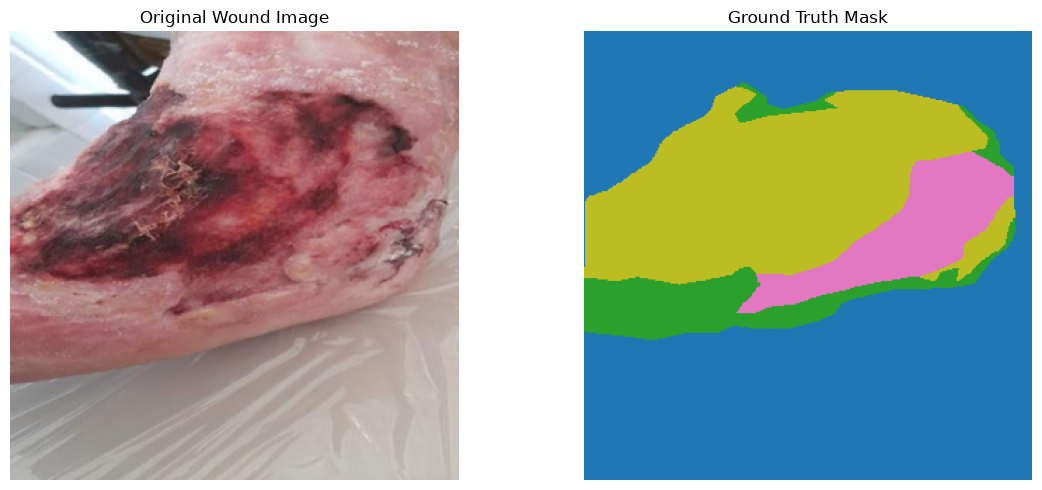

In [25]:
import matplotlib.pyplot as plt

# Ubah tensor gambar dari [C, H, W] menjadi [H, W, C]
image_np = image.permute(1, 2, 0).cpu().numpy()

# Ubah tensor mask menjadi NumPy array
mask_np = mask.cpu().numpy()

# Buat dua area visualisasi
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gambar asli
axes[0].imshow(image_np)
axes[0].set_title("Original Wound Image")
axes[0].axis("off")

# Ground Truth
axes[1].imshow(mask_np, cmap="tab10", vmin=0, vmax=5)
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [26]:
# Siapkan input dengan batch dimension
input_tensor = image.unsqueeze(0).to(device)

# Jalankan inference tanpa menghitung gradient
with torch.inference_mode():
    logits = model(input_tensor)

    # Pilih kelas dengan skor tertinggi
    prediction = torch.argmax(logits, dim=1)

# Pindahkan hasil prediksi ke CPU
pred_mask = prediction.squeeze(0).cpu().numpy()

print("Input shape:", input_tensor.shape)
print("Logits shape:", logits.shape)
print("Prediction shape:", pred_mask.shape)
print("Predicted classes:", sorted(set(pred_mask.flatten().tolist())))

Input shape: torch.Size([1, 3, 320, 320])
Logits shape: torch.Size([1, 6, 320, 320])
Prediction shape: (320, 320)
Predicted classes: [0, 1]


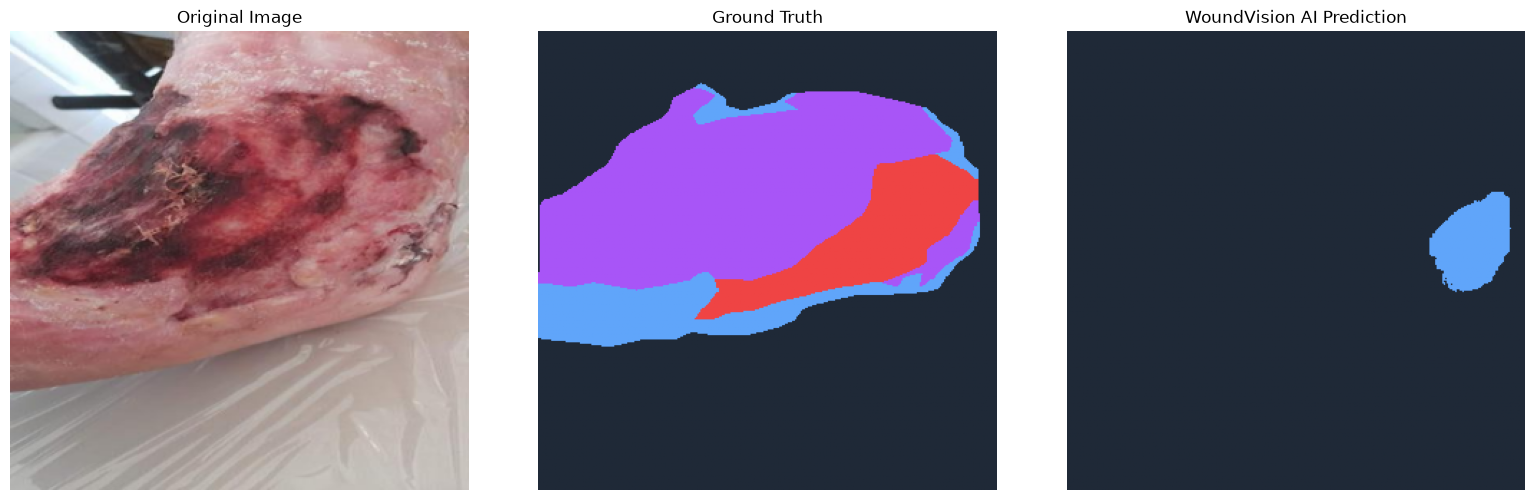

In [28]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Warna untuk 6 kelas jaringan
colors = [
    "#1F2937",  # Background
    "#60A5FA",  # Epithelial
    "#FACC15",  # Slough
    "#EF4444",  # Granulation
    "#A855F7",  # Necrotic
    "#9CA3AF"   # Other
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(range(7), cmap.N)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original image
axes[0].imshow(image_np)
axes[0].set_title("Original Image")

# Ground truth
axes[1].imshow(mask_np, cmap=cmap, norm=norm)
axes[1].set_title("Ground Truth")

# AI prediction
axes[2].imshow(pred_mask, cmap=cmap, norm=norm)
axes[2].set_title("WoundVision AI Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
import numpy as np

class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

print("=== PER-IMAGE EVALUATION ===")

for class_id, class_name in enumerate(class_names):

    gt = mask_np == class_id
    pred = pred_mask == class_id

    intersection = np.logical_and(gt, pred).sum()

    gt_pixels = gt.sum()
    pred_pixels = pred.sum()

    total = gt_pixels + pred_pixels

    dice = (
        (2 * intersection) / total
        if total > 0 else None
    )

    dice_text = f"{dice:.4f}" if dice is not None else "N/A"

    print(
        f"{class_name:12s} | "
        f"GT: {gt_pixels:6d} | "
        f"Pred: {pred_pixels:6d} | "
        f"Dice: {dice_text}"
    )

=== PER-IMAGE EVALUATION ===
Background   | GT:  60124 | Pred:  99630 | Dice: 0.7483
Epithelial   | GT:   7795 | Pred:   2770 | Dice: 0.0627
Slough       | GT:      0 | Pred:      0 | Dice: N/A
Granulation  | GT:   7979 | Pred:      0 | Dice: 0.0000
Necrotic     | GT:  26502 | Pred:      0 | Dice: 0.0000
Other        | GT:      0 | Pred:      0 | Dice: N/A


In [30]:
# Buat model baru khusus CPU
cpu_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
)

# Gunakan bobot checkpoint yang sama
cpu_model.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

cpu_model.eval()

# Inference menggunakan CPU
with torch.inference_mode():
    cpu_logits = cpu_model(
        image.unsqueeze(0).cpu()
    )

    cpu_pred = cpu_logits.argmax(
        dim=1
    ).squeeze(0).numpy()

# Bandingkan hasil CPU dengan MPS
difference = np.mean(cpu_pred != pred_mask)

print("=== CPU vs MPS ===")
print("CPU classes:", np.unique(cpu_pred))
print("MPS classes:", np.unique(pred_mask))
print(f"Pixel berbeda: {difference * 100:.2f}%")

=== CPU vs MPS ===
CPU classes: [0 1]
MPS classes: [0 1]
Pixel berbeda: 0.00%


In [31]:
import numpy as np
import torch

classes = {
    2: "Slough",
    3: "Granulation",
    4: "Necrotic"
}

intersection = np.zeros(3)
total_pixels = np.zeros(3)
detected_images = np.zeros(3, dtype=int)

model.eval()

with torch.inference_mode():

    for i in range(len(val_dataset)):

        img, gt = val_dataset[i]

        logits = model(
            img.unsqueeze(0).to(device)
        )

        pred = logits.argmax(dim=1).squeeze(0).cpu()

        for j, class_id in enumerate(classes):

            gt_class = gt == class_id
            pred_class = pred == class_id

            intersection[j] += (
                gt_class & pred_class
            ).sum().item()

            total_pixels[j] += (
                gt_class.sum() + pred_class.sum()
            ).item()

            if pred_class.any().item():
                detected_images[j] += 1

# Hitung Dice per kelas
dice_scores = []

print("=== VALIDATION RESULTS ===")

for j, name in enumerate(classes.values()):

    dice = (
        2 * intersection[j] / total_pixels[j]
        if total_pixels[j] > 0 else np.nan
    )

    dice_scores.append(dice)

    print(
        f"{name}: Dice={dice:.4f} | "
        f"Predicted in {detected_images[j]}/30 images"
    )

print("\nPooled Clinical-3 Dice:",
      round(float(np.nanmean(dice_scores)), 4))

=== VALIDATION RESULTS ===
Slough: Dice=0.1984 | Predicted in 7/30 images
Granulation: Dice=0.0000 | Predicted in 0/30 images
Necrotic: Dice=0.0000 | Predicted in 0/30 images

Pooled Clinical-3 Dice: 0.0661


In [32]:
import ast

eval_path = PROJECT_DIR / "src/woundvision/evaluate.py"

eval_source = eval_path.read_text(encoding="utf-8")
eval_tree = ast.parse(eval_source)

print("=== EVALUATION IMPORTS ===")

for node in eval_tree.body:
    if isinstance(node, (ast.Import, ast.ImportFrom)):
        print(ast.get_source_segment(eval_source, node))

print("\n=== EVALUATION FUNCTIONS ===")

for node in eval_tree.body:
    if isinstance(node, ast.FunctionDef):
        print(
            f"{node.name}({ast.unparse(node.args)})"
        )

print("\n=== EVALUATION KEYWORDS ===")

keywords = [
    "eval(",
    "argmax",
    "dice",
    "WoundDataset",
    "DataLoader"
]

for number, line in enumerate(
    eval_source.splitlines(), start=1
):
    if any(word in line for word in keywords):
        print(f"{number}: {line.strip()}")

=== EVALUATION IMPORTS ===
import torch

=== EVALUATION FUNCTIONS ===
evaluate_model(model, val_loader, device)
calculate_metrics(cm)

=== EVALUATION KEYWORDS ===
14: model.eval()
32: predictions = logits.argmax(dim=1).cpu()
43: indices = (
49: indices.long(),
65: dice = (
73: macro_tissue_dice = dice[1:6].mean()
80: wound_dice = (
87: "macro_tissue_dice": macro_tissue_dice.item(),
88: "wound_dice": wound_dice.item(),
89: "dice_per_class": dice.tolist()


In [34]:
from torch.utils.data import DataLoader
from woundvision.evaluate import evaluate_model

# Buat DataLoader validasi
val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

# Evaluasi menggunakan fungsi asli project
eval_results = evaluate_model(
    model,
    val_loader,
    device
)

# Bandingkan Dice Score
class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

print("=== ORIGINAL EVALUATOR ===")

for i, name in enumerate(class_names):
    dice = eval_results["dice_per_class"][i]
    print(f"{name}: {float(dice):.4f}")

# Rata-rata Dice untuk 3 kelas klinis
clinical_dice = sum(
    float(eval_results["dice_per_class"][i])
    for i in [2, 3, 4]
) / 3

print("\n=== COMPARISON ===")
print("Mac Clinical-3 Dice:", round(clinical_dice, 4))
print(
    "Checkpoint Clinical-3 Dice:",
    round(checkpoint["clinical_3_dice"], 4)
)

=== ORIGINAL EVALUATOR ===


/var/folders/0d/28ch67w178d_7jvkjx3q14kc0000gn/T/ipykernel_11393/3448051980.py:32: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:381.)
  dice = eval_results["dice_per_class"][i]


IndexError: too many indices for tensor of dimension 2

In [35]:
from woundvision.evaluate import calculate_metrics

# Periksa output evaluator
print("Output type:", type(eval_results).__name__)
print("Output shape:", eval_results.shape)

# Ubah Confusion Matrix menjadi metrik
original_metrics = calculate_metrics(eval_results)

# Ambil Dice setiap kelas
dice_scores = original_metrics["dice_per_class"]

class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

print("\n=== ORIGINAL EVALUATION ===")

for i, name in enumerate(class_names):
    print(f"{name}: {float(dice_scores[i]):.4f}")

# Hitung rata-rata tiga kelas utama
clinical_dice = sum(
    float(dice_scores[i])
    for i in [2, 3, 4]
) / 3

print("\n=== COMPARISON ===")
print("Mac Clinical-3 Dice:", round(clinical_dice, 4))
print("Windows Checkpoint:", round(checkpoint["clinical_3_dice"], 4))

Output type: Tensor
Output shape: torch.Size([6, 6])

=== ORIGINAL EVALUATION ===
Background: 0.9567
Epithelial: 0.3353
Slough: 0.3455
Granulation: 0.7052
Necrotic: 0.4849
Other: 0.0000

=== COMPARISON ===
Mac Clinical-3 Dice: 0.5118
Windows Checkpoint: 0.5118


In [36]:
import inspect

print("=== ORIGINAL EVALUATION FUNCTION ===")

print(inspect.getsource(evaluate_model))

=== ORIGINAL EVALUATION FUNCTION ===
def evaluate_model(model, val_loader, device):
    """Evaluate all validation images."""

    model.eval()

    cm = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long
    )

    mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=device).view(1, 3, 1, 1)

    with torch.inference_mode():
        for images, masks in val_loader:

            # Same preprocessing as Google Colab
            images = images.to(device)
            images = (images - mean) / std

            logits = model(images)
            predictions = logits.argmax(dim=1).cpu()

            masks = masks.cpu()

            # Ignore unlabeled pixels
            valid = (
                (masks != 255)
                & (masks >= 0)
                & (masks < NUM_CLASSES)
            )

            indices = (
                masks[valid] * NUM_CLASSES
                + predictions[valid]
            )

            cm +=

In [37]:
from woundvision.evaluate import MEAN, STD

# Siapkan mean dan std sesuai pipeline asli
mean = torch.tensor(
    MEAN, device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    STD, device=device
).view(1, 3, 1, 1)

# Ambil gambar validasi pertama
image, mask = val_dataset[0]

# Tambahkan dimensi batch dan pindahkan ke GPU
input_tensor = image.unsqueeze(0).to(device)

# Terapkan normalisasi yang sama dengan evaluator
input_normalized = (input_tensor - mean) / std

# Jalankan inference
model.eval()

with torch.inference_mode():
    logits = model(input_normalized)
    prediction = logits.argmax(dim=1)

pred_mask = prediction.squeeze(0).cpu().numpy()

print("Device:", device)
print("Input shape:", input_normalized.shape)
print("Predicted classes:", np.unique(pred_mask))
print("Ground Truth classes:", torch.unique(mask).tolist())

Device: mps
Input shape: torch.Size([1, 3, 320, 320])
Predicted classes: [0 1 3 4]
Ground Truth classes: [0, 1, 3, 4]


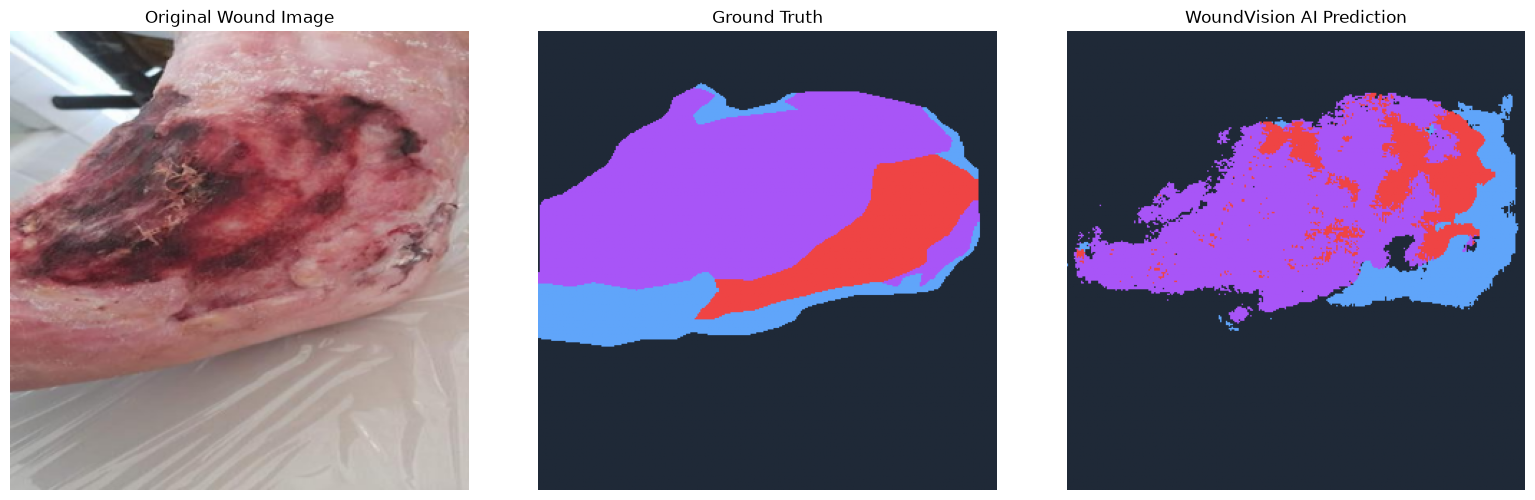

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image_np)
axes[0].set_title("Original Wound Image")

axes[1].imshow(mask_np, cmap=cmap, norm=norm)
axes[1].set_title("Ground Truth")

axes[2].imshow(pred_mask, cmap=cmap, norm=norm)
axes[2].set_title("WoundVision AI Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
import numpy as np

class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

print("=== DICE SCORE - IMAGE 1 ===")

for class_id, name in enumerate(class_names):

    gt = mask_np == class_id
    pred = pred_mask == class_id

    intersection = np.logical_and(gt, pred).sum()

    total = gt.sum() + pred.sum()

    dice = (
        2 * intersection / total
        if total > 0 else np.nan
    )

    print(
        f"{name:12s} | "
        f"Dice: {dice:.4f} | "
        f"GT: {gt.sum():6d} | "
        f"Pred: {pred.sum():6d}"
    )

=== DICE SCORE - IMAGE 1 ===
Background   | Dice: 0.8859 | GT:  60124 | Pred:  71104
Epithelial   | Dice: 0.1937 | GT:   7795 | Pred:   5930
Slough       | Dice: nan | GT:      0 | Pred:      0
Granulation  | Dice: 0.3400 | GT:   7979 | Pred:   5757
Necrotic     | Dice: 0.6824 | GT:  26502 | Pred:  19609
Other        | Dice: nan | GT:      0 | Pred:      0


In [40]:
slough_samples = []

for idx in range(len(val_dataset)):

    image_i, mask_i = val_dataset[idx]

    slough_pixels = (mask_i == 2).sum().item()

    if slough_pixels > 0:
        slough_samples.append((idx, slough_pixels))

# Urutkan berdasarkan jumlah piksel Slough terbanyak
slough_samples.sort(
    key=lambda x: x[1],
    reverse=True
)

print("Images containing Slough:", len(slough_samples))

print("\nTop 5 Slough Samples:")

for idx, pixels in slough_samples[:5]:
    print(f"Image {idx}: {pixels} pixels")

Images containing Slough: 23

Top 5 Slough Samples:
Image 18: 7251 pixels
Image 24: 5960 pixels
Image 21: 4010 pixels
Image 22: 3836 pixels
Image 11: 3353 pixels


In [41]:
# Pilih sampel dengan Slough terbanyak
sample_idx = slough_samples[0][0]

# Ambil gambar dan ground truth
slough_image, slough_mask = val_dataset[sample_idx]

# Siapkan input untuk GPU M1
x = slough_image.unsqueeze(0).to(device)

# Normalisasi sesuai pipeline training
x = (x - mean) / std

# Jalankan inference
model.eval()

with torch.inference_mode():
    slough_logits = model(x)
    slough_prediction = slough_logits.argmax(dim=1)

# Konversi hasil untuk visualisasi
slough_image_np = slough_image.permute(1, 2, 0).cpu().numpy()
slough_gt_np = slough_mask.cpu().numpy()
slough_pred_np = slough_prediction.squeeze(0).cpu().numpy()

print("Sample index:", sample_idx)
print("Ground Truth classes:", np.unique(slough_gt_np))
print("Predicted classes:", np.unique(slough_pred_np))

Sample index: 18
Ground Truth classes: [0 1 2 3 4]
Predicted classes: [0 1 2 3 4]


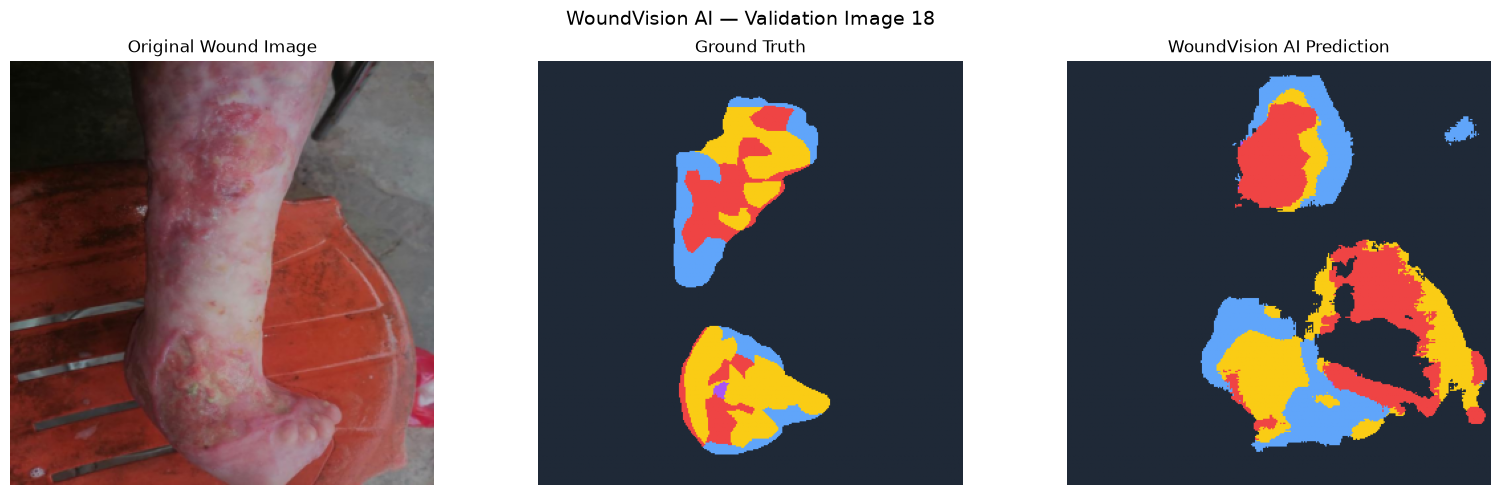

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Foto luka asli
axes[0].imshow(slough_image_np)
axes[0].set_title("Original Wound Image")

# 2. Ground Truth
axes[1].imshow(
    slough_gt_np,
    cmap=cmap,
    norm=norm
)
axes[1].set_title("Ground Truth")

# 3. Hasil prediksi WoundVision AI
axes[2].imshow(
    slough_pred_np,
    cmap=cmap,
    norm=norm
)
axes[2].set_title("WoundVision AI Prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"WoundVision AI — Validation Image {sample_idx}",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [43]:
class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

print("=== EVALUATION IMAGE 18 ===")

for class_id, name in enumerate(class_names):

    # Piksel Ground Truth dan prediksi
    gt = slough_gt_np == class_id
    pred = slough_pred_np == class_id

    # Hitung jumlah piksel
    gt_pixels = gt.sum()
    pred_pixels = pred.sum()

    # Hitung area yang beririsan
    intersection = np.logical_and(gt, pred).sum()

    # Hitung Dice Score
    total = gt_pixels + pred_pixels

    dice = (
        2 * intersection / total
        if total > 0 else np.nan
    )

    print(
        f"{name:12s} | "
        f"Dice: {dice:.4f} | "
        f"GT: {gt_pixels:6d} | "
        f"Pred: {pred_pixels:6d}"
    )

=== EVALUATION IMAGE 18 ===
Background   | Dice: 0.8881 | GT:  86521 | Pred:  78052
Epithelial   | Dice: 0.2074 | GT:   4017 | Pred:   7688
Slough       | Dice: 0.3640 | GT:   7251 | Pred:   7749
Granulation  | Dice: 0.2425 | GT:   4518 | Pred:   8900
Necrotic     | Dice: 0.0000 | GT:     93 | Pred:     11
Other        | Dice: nan | GT:      0 | Pred:      0


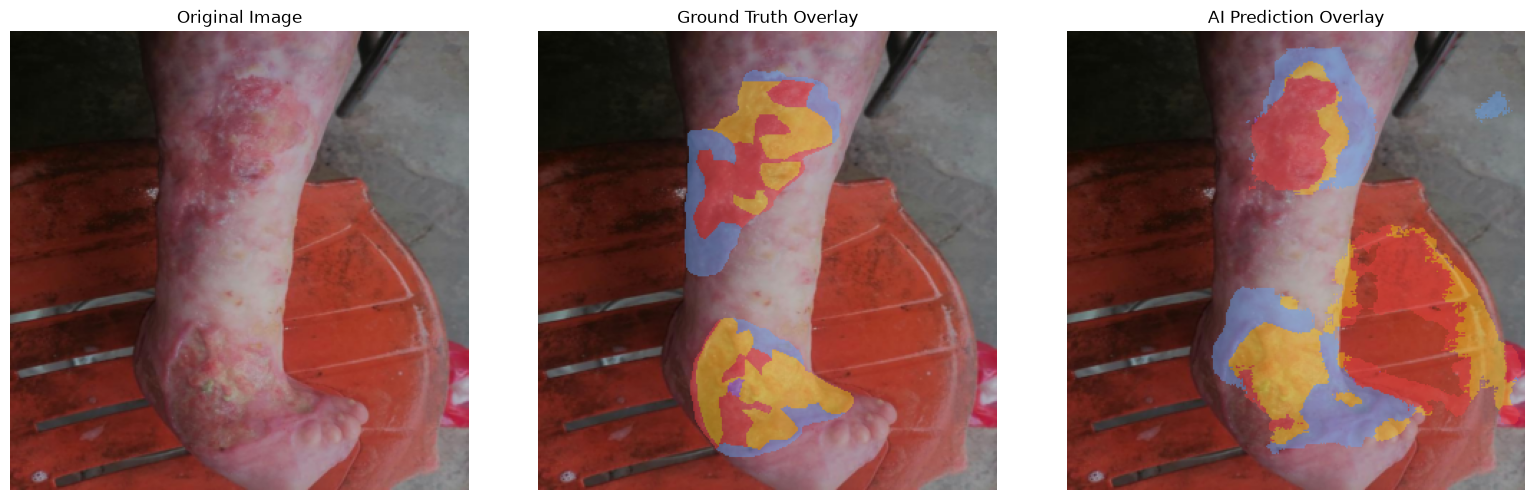

In [44]:
# Sembunyikan label background (0) dari overlay
gt_overlay = np.ma.masked_where(
    slough_gt_np == 0,
    slough_gt_np
)

pred_overlay = np.ma.masked_where(
    slough_pred_np == 0,
    slough_pred_np
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original image
axes[0].imshow(slough_image_np)
axes[0].set_title("Original Image")

# Ground Truth overlay
axes[1].imshow(slough_image_np)
axes[1].imshow(
    gt_overlay,
    cmap=cmap,
    norm=norm,
    alpha=0.45
)
axes[1].set_title("Ground Truth Overlay")

# AI Prediction overlay
axes[2].imshow(slough_image_np)
axes[2].imshow(
    pred_overlay,
    cmap=cmap,
    norm=norm,
    alpha=0.45
)
axes[2].set_title("AI Prediction Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

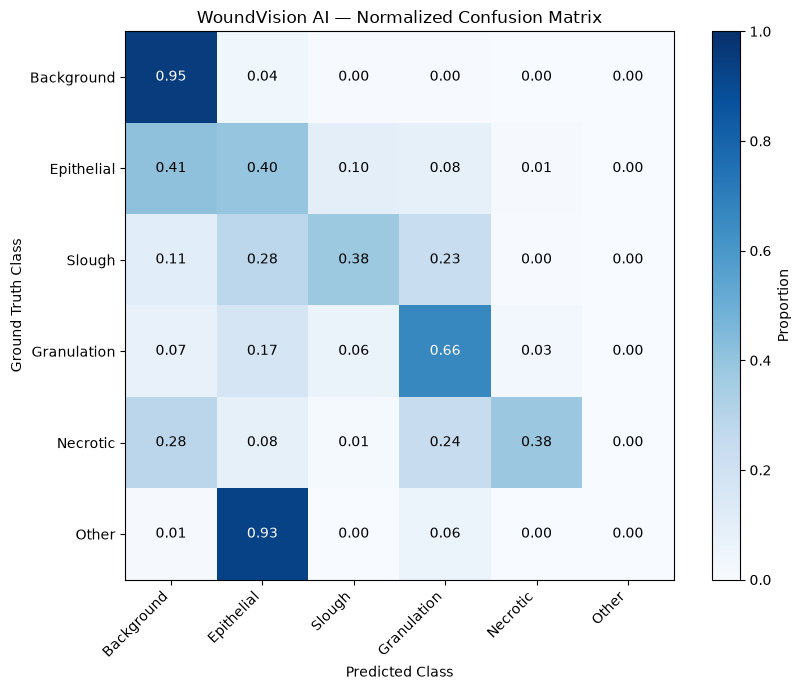

In [45]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

# Ambil confusion matrix dari evaluator asli
cm = eval_results.cpu().numpy()

# Normalisasi berdasarkan kelas Ground Truth
row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# Visualisasi
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(6), labels=class_names, rotation=45, ha="right")
ax.set_yticks(range(6), labels=class_names)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Ground Truth Class")
ax.set_title("WoundVision AI — Normalized Confusion Matrix")

# Tampilkan nilai pada setiap sel
for i in range(6):
    for j in range(6):
        value = cm_normalized[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Proportion")
plt.tight_layout()
plt.show()

In [46]:
clinical_classes = {
    2: "Slough",
    3: "Granulation",
    4: "Necrotic"
}

print("=== CLINICAL TISSUE METRICS ===")

for class_id, name in clinical_classes.items():

    TP = cm[class_id, class_id]

    FP = cm[:, class_id].sum() - TP

    FN = cm[class_id, :].sum() - TP

    precision = TP / (TP + FP) if TP + FP > 0 else 0

    recall = TP / (TP + FN) if TP + FN > 0 else 0

    dice = 2 * TP / (2 * TP + FP + FN) \
        if 2 * TP + FP + FN > 0 else 0

    print(f"\n{name}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"Dice      : {dice:.4f}")
    print(f"FP pixels : {FP}")
    print(f"FN pixels : {FN}")

=== CLINICAL TISSUE METRICS ===

Slough
Precision : 0.3176
Recall    : 0.3787
Dice      : 0.3455
FP pixels : 40531
FN pixels : 30953

Granulation
Precision : 0.7543
Recall    : 0.6621
Dice      : 0.7052
FP pixels : 47857
FN pixels : 74958

Necrotic
Precision : 0.6640
Recall    : 0.3818
Dice      : 0.4849
FP pixels : 9064
FN pixels : 28999


In [47]:
from pathlib import Path

files = [
    PROJECT_DIR / "src/woundvision/train.py",
    PROJECT_DIR / "scripts/run_training.py"
]

keywords = [
    "loss",
    "criterion",
    "optimizer",
    "weight",
    "learning_rate",
    "scheduler"
]

for file in files:
    print(f"\n=== {file.name} ===")

    lines = file.read_text(encoding="utf-8").splitlines()

    for number, line in enumerate(lines, start=1):
        if any(
            word in line.lower()
            for word in keywords
        ):
            print(f"{number}: {line.strip()}")


=== train.py ===
6: from .config import CLASS_WEIGHTS
13: optimizer,
15: class_weights=None
30: # Weighted Cross Entropy
31: selected_weights = (
32: CLASS_WEIGHTS
33: if class_weights is None
34: else class_weights
37: weights = torch.tensor(
38: selected_weights,
43: ce_loss = nn.CrossEntropyLoss(
44: weight=weights,
48: # Dice Loss
49: dice_loss = smp.losses.DiceLoss(
55: total_loss = 0.0
64: optimizer.zero_grad()
69: # Hitung loss
70: loss = (
71: ce_loss(outputs, masks)
72: + dice_loss(outputs, masks)
75: if not torch.isfinite(loss):
76: raise RuntimeError("Non-finite training loss")
79: loss.backward()
82: optimizer.step()
84: total_loss += loss.item()
86: return total_loss / len(loader)

=== run_training.py ===
19: CLASS_WEIGHTS
40: "--necrotic-weight",
49: assert math.isfinite(args.necrotic_weight)
50: assert args.necrotic_weight > 0
52: class_weights = CLASS_WEIGHTS.copy()
53: class_weights[4] = args.necrotic_weight
107: weights_only=True
114: # 5. Optimizer
115: optimizer = 

In [48]:
train_path = PROJECT_DIR / "src/woundvision/train.py"

lines = train_path.read_text(
    encoding="utf-8"
).splitlines()

print("=== LOSS FUNCTION CONFIGURATION ===")

for i in range(25, 75):
    print(f"{i+1:3d}: {lines[i]}")

=== LOSS FUNCTION CONFIGURATION ===
 26:     std = torch.tensor(
 27:         STD, device=device
 28:     ).view(1, 3, 1, 1)
 29: 
 30:     # Weighted Cross Entropy
 31:     selected_weights = (
 32:         CLASS_WEIGHTS
 33:         if class_weights is None
 34:         else class_weights
 35:     )
 36: 
 37:     weights = torch.tensor(
 38:         selected_weights,
 39:         device=device,
 40:         dtype=torch.float32
 41:     )
 42: 
 43:     ce_loss = nn.CrossEntropyLoss(
 44:         weight=weights,
 45:         ignore_index=255
 46:     )
 47: 
 48:     # Dice Loss
 49:     dice_loss = smp.losses.DiceLoss(
 50:         mode="multiclass",
 51:         from_logits=True,
 52:         ignore_index=255
 53:     )
 54: 
 55:     total_loss = 0.0
 56: 
 57:     for images, masks in loader:
 58: 
 59:         images = images.to(device)
 60:         masks = masks.to(device)
 61: 
 62:         images = (images - mean) / std
 63: 
 64:         optimizer.zero_grad()
 65: 
 66:     

In [49]:
print("=== DICE LOSS CONFIGURATION ===")

for i in range(42, 55):
    print(f"{i+1}: {lines[i]}")

print("\n=== TOTAL LOSS ===")

for i in range(68, 74):
    print(f"{i+1}: {lines[i]}")

=== DICE LOSS CONFIGURATION ===
43:     ce_loss = nn.CrossEntropyLoss(
44:         weight=weights,
45:         ignore_index=255
46:     )
47: 
48:     # Dice Loss
49:     dice_loss = smp.losses.DiceLoss(
50:         mode="multiclass",
51:         from_logits=True,
52:         ignore_index=255
53:     )
54: 
55:     total_loss = 0.0

=== TOTAL LOSS ===
69:         # Hitung loss
70:         loss = (
71:             ce_loss(outputs, masks)
72:             + dice_loss(outputs, masks)
73:         )
74: 


In [50]:
from torch import nn
from torch.utils.data import DataLoader

# Ambil data training
train_dataset = WoundDataset(
    root_dir=PROJECT_DIR / "data" / "LUTSeg",
    split_file="train.txt",
    image_size=320
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

images, masks = next(iter(train_loader))

# Preprocessing sesuai training sebelumnya
images = (images.to(device) - mean) / std
masks = masks.to(device)

# Class weights eksperimen terakhir
weights = torch.tensor(
    config["class_weights"],
    dtype=torch.float32,
    device=device
)

# Definisikan dua loss function
ce_fn = nn.CrossEntropyLoss(
    weight=weights,
    ignore_index=255
)

dice_fn = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True,
    ignore_index=255
)

# Hitung loss tanpa training
model.eval()

with torch.inference_mode():
    outputs = model(images)

    ce_value = ce_fn(outputs, masks)
    dice_value = dice_fn(outputs, masks)

print("=== LOSS ANALYSIS ===")
print(f"Cross Entropy : {ce_value.item():.4f}")
print(f"Dice Loss     : {dice_value.item():.4f}")
print(f"Total Loss    : {(ce_value + dice_value).item():.4f}")

=== LOSS ANALYSIS ===
Cross Entropy : 0.9978
Dice Loss     : 0.4799
Total Loss    : 1.4776


In [51]:
train_path = PROJECT_DIR / "src/woundvision/train.py"

source_lines = train_path.read_text(
    encoding="utf-8"
).splitlines()

keywords = [
    "optim.Adam",
    "optim.SGD",
    "optimizer =",
    "learning_rate",
    "lr=",
    "load_state_dict",
    "manual_seed"
]

print("=== TRAINING CONFIGURATION ===")

for i, line in enumerate(source_lines):
    if any(keyword in line for keyword in keywords):
        start = max(0, i - 2)
        end = min(len(source_lines), i + 4)

        print(f"\n--- Lines {start+1}-{end} ---")

        for j in range(start, end):
            print(f"{j+1}: {source_lines[j]}")

=== TRAINING CONFIGURATION ===


In [52]:
import re

print("=== OPTIMIZER CONFIGURATION ===")

# Cari di seluruh source code project
python_files = list(
    (PROJECT_DIR / "src").rglob("*.py")
) + list(
    (PROJECT_DIR / "scripts").rglob("*.py")
)

keywords = r"optimizer|optim|learning_rate|\blr\s*=|weight_decay|manual_seed"

for file in python_files:
    lines = file.read_text(encoding="utf-8").splitlines()

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, start=1)
        if re.search(keywords, line, re.IGNORECASE)
    ]

    if matches:
        print(f"\n=== {file.relative_to(PROJECT_DIR)} ===")

        for line_num, line in matches[:15]:
            print(f"{line_num}: {line}")

=== OPTIMIZER CONFIGURATION ===

=== src/woundvision/config.py ===
21: LEARNING_RATE = 1e-4
22: WEIGHT_DECAY = 1e-4

=== src/woundvision/train.py ===
13: optimizer,
64: optimizer.zero_grad()
82: optimizer.step()

=== scripts/check_training.py ===
59: # 5. Siapkan optimizer
60: optimizer = torch.optim.AdamW(
62: lr=1e-4,
63: weight_decay=1e-4
77: optimizer,

=== scripts/run_training.py ===
60: torch.manual_seed(SEED)
89: generator=torch.Generator().manual_seed(SEED)
114: # 5. Optimizer
115: optimizer = torch.optim.AdamW(
117: lr=1e-4,
118: weight_decay=1e-4
196: optimizer,
286: "optimizer_state": optimizer.state_dict(),


In [53]:
optimizer_state = checkpoint["optimizer_state"]

print("=== SAVED OPTIMIZER SETTINGS ===")

for group in optimizer_state["param_groups"]:
    print("Learning Rate:", group.get("lr"))
    print("Weight Decay:", group.get("weight_decay"))
    print("Betas:", group.get("betas"))

=== SAVED OPTIMIZER SETTINGS ===
Learning Rate: 0.0001
Weight Decay: 0.0001
Betas: (0.9, 0.999)


In [54]:
run_path = PROJECT_DIR / "scripts/run_training.py"

run_lines = run_path.read_text(
    encoding="utf-8"
).splitlines()

print("=== DATA LOADING & OPTIMIZER ===")

for i in range(74, 125):
    print(f"{i+1}: {run_lines[i]}")

=== DATA LOADING & OPTIMIZER ===
75: # 3. Dataset
76: train_dataset = WoundDataset(DATA_ROOT, "train.txt")
77: val_dataset = WoundDataset(DATA_ROOT, "val.txt")
78: 
79: # Batasi data untuk pengujian pipeline
80: if args.max_train_samples > 0:
81:     n = min(args.max_train_samples, len(train_dataset))
82:     train_dataset = Subset(train_dataset, range(n))
83: 
84: train_loader = DataLoader(
85:     train_dataset,
86:     batch_size=args.batch_size,
87:     shuffle=True,
88:     num_workers=0,
89:     generator=torch.Generator().manual_seed(SEED)
90: 
91: )
92: 
93: val_loader = DataLoader(
94:     val_dataset,
95:     batch_size=args.batch_size,
96:     shuffle=False,
97:     num_workers=0
98: )
99: 
100: 
101: # 4. Load model V0.2
102: model = build_model()
103: 
104: checkpoint = torch.load(
105:     CHECKPOINT_V02,
106:     map_location="cpu",
107:     weights_only=True
108: )
109: 
110: model.load_state_dict(checkpoint["model_state"])
111: model.to(device)
112: 
113: 
114: # 5. Op

In [55]:
from torch.utils.data import DataLoader

SEED = 42
BATCH_SIZE = 2
EPOCHS = 3

def create_dataloaders(seed=SEED):

    train_ds = WoundDataset(
        root_dir=PROJECT_DIR / "data" / "LUTSeg",
        split_file="train.txt",
        image_size=320
    )

    val_ds = WoundDataset(
        root_dir=PROJECT_DIR / "data" / "LUTSeg",
        split_file="val.txt",
        image_size=320
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed)
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader


train_loader_v4a, val_loader_v4a = create_dataloaders()

print("=== V4 DATASET ===")
print("Train images:", len(train_loader_v4a.dataset))
print("Validation images:", len(val_loader_v4a.dataset))
print("Train batches:", len(train_loader_v4a))
print("Validation batches:", len(val_loader_v4a))

=== V4 DATASET ===
Train images: 111
Validation images: 30
Train batches: 56
Validation batches: 15


In [56]:
# Reproducibility
torch.manual_seed(SEED)

# 1. Bangun arsitektur yang sama
model_v4a = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
)

# 2. Load bobot terbaik dari V3
model_v4a.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

# 3. Pindahkan ke GPU Mac M1
model_v4a = model_v4a.to(device)

# 4. Buat optimizer baru
optimizer_v4a = torch.optim.AdamW(
    model_v4a.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("=== V4-A MODEL ===")
print("Device:", next(model_v4a.parameters()).device)
print("Starting checkpoint epoch:", checkpoint["epoch"])
print("Optimizer:", type(optimizer_v4a).__name__)
print("Learning rate:", optimizer_v4a.param_groups[0]["lr"])
print("Weight decay:", optimizer_v4a.param_groups[0]["weight_decay"])

=== V4-A MODEL ===
Device: mps:0
Starting checkpoint epoch: 3
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001


In [57]:
import torch.nn as nn

# Pastikan konfigurasi berasal dari eksperimen V3 terakhir
assert config["run_id"] == "20261121_185427_e291f3"

# 1. Ambil class weights dari konfigurasi V3
class_weights_v4a = torch.tensor(
    config["class_weights"],
    dtype=torch.float32,
    device=device
)

# 2. Weighted Cross Entropy
ce_loss_v4a = nn.CrossEntropyLoss(
    weight=class_weights_v4a,
    ignore_index=255
)

# 3. Multiclass Dice Loss
dice_loss_v4a = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True,
    ignore_index=255
)

print("=== V4-A LOSS CONFIGURATION ===")
print("CE Loss:", type(ce_loss_v4a).__name__)
print("Dice Loss:", type(dice_loss_v4a).__name__)
print("Class weights:", class_weights_v4a.tolist())

=== V4-A LOSS CONFIGURATION ===
CE Loss: CrossEntropyLoss
Dice Loss: DiceLoss
Class weights: [0.25, 1.0, 1.3411999940872192, 1.0134999752044678, 6.0, 1.0]


In [58]:
from woundvision.evaluate import evaluate_model, calculate_metrics

# Epoch pertama eksperimen V4-A
model_v4a.train()

total_loss = 0.0
total_images = 0

for images, masks in train_loader_v4a:

    # 1. Pindahkan data ke GPU M1
    images = images.to(device)
    masks = masks.to(device)

    # 2. Normalisasi sesuai pipeline training
    images = (images - mean) / std

    # 3. Reset gradient
    optimizer_v4a.zero_grad(set_to_none=True)

    # 4. Forward pass
    outputs = model_v4a(images)

    # 5. Hitung loss
    loss = (
        ce_loss_v4a(outputs, masks)
        + dice_loss_v4a(outputs, masks)
    )

    if not torch.isfinite(loss).item():
        raise RuntimeError("Non-finite loss detected")

    # 6. Backpropagation
    loss.backward()

    # 7. Update bobot model
    optimizer_v4a.step()

    # 8. Catat training loss
    batch_size = images.size(0)
    total_loss += loss.item() * batch_size
    total_images += batch_size

train_loss = total_loss / total_images

# Evaluasi menggunakan pipeline asli
cm_v4a = evaluate_model(
    model_v4a,
    val_loader_v4a,
    device
)

metrics_v4a = calculate_metrics(cm_v4a)
dice = metrics_v4a["dice_per_class"]

clinical_dice = sum(
    float(dice[i]) for i in [2, 3, 4]
) / 3

print("=== V4-A EPOCH 1 ===")
print(f"Train Loss: {train_loss:.4f}")
print(f"Slough Dice: {float(dice[2]):.4f}")
print(f"Granulation Dice: {float(dice[3]):.4f}")
print(f"Necrotic Dice: {float(dice[4]):.4f}")
print(f"Clinical-3 Dice: {clinical_dice:.4f}")

=== V4-A EPOCH 1 ===
Train Loss: 0.6825
Slough Dice: 0.2891
Granulation Dice: 0.6802
Necrotic Dice: 0.1980
Clinical-3 Dice: 0.3891


In [59]:
# Folder hasil eksperimen V4-A
run_dir_v4a = PROJECT_DIR / "runs" / "notebook_v4a_mps"
run_dir_v4a.mkdir(parents=True, exist_ok=True)

# Lokasi checkpoint epoch pertama
save_path = run_dir_v4a / "epoch_01.pth"

# Hindari menimpa checkpoint tanpa sengaja
if save_path.exists():
    raise FileExistsError(f"Checkpoint sudah ada: {save_path}")

# Simpan model dan optimizer
torch.save({
    "epoch": 1,
    "model_state": {
        k: v.detach().cpu()
        for k, v in model_v4a.state_dict().items()
    },
    "optimizer_state": optimizer_v4a.state_dict(),
    "train_loss": train_loss,
    "clinical_3_dice": clinical_dice,
    "dice_per_class": dice.detach().cpu().tolist(),
    "starting_checkpoint": str(checkpoint_path)
}, save_path)

print("Checkpoint saved:", save_path)
print("Clinical-3 Dice:", round(clinical_dice, 4))

AttributeError: 'list' object has no attribute 'detach'

In [60]:
# Folder hasil eksperimen V4-A
run_dir_v4a = PROJECT_DIR / "runs" / "notebook_v4a_mps"
run_dir_v4a.mkdir(parents=True, exist_ok=True)

# Lokasi checkpoint
save_path = run_dir_v4a / "epoch_01.pth"

if save_path.exists():
    raise FileExistsError(f"Checkpoint sudah ada: {save_path}")

# Simpan model dan optimizer
torch.save({
    "epoch": 1,

    "model_state": {
        k: v.detach().cpu()
        for k, v in model_v4a.state_dict().items()
    },

    "optimizer_state": optimizer_v4a.state_dict(),

    "train_loss": float(train_loss),

    "clinical_3_dice": float(clinical_dice),

    "dice_per_class": [
        float(value) for value in dice
    ],

    "starting_checkpoint": str(checkpoint_path)

}, save_path)

print("Checkpoint saved:", save_path)
print("Clinical-3 Dice:", round(clinical_dice, 4))

Checkpoint saved: /Users/salman/Projects/AI/WoundVision-AI/runs/notebook_v4a_mps/epoch_01.pth
Clinical-3 Dice: 0.3891


In [61]:
# === V4-A EPOCH 2 ===

# Pastikan checkpoint epoch pertama sudah tersimpan
assert (run_dir_v4a / "epoch_01.pth").exists()

# Hindari training ulang epoch 2 secara tidak sengaja
save_path_ep2 = run_dir_v4a / "epoch_02.pth"

if save_path_ep2.exists():
    raise FileExistsError("Epoch 2 sudah tersimpan!")

# 1. Aktifkan training mode
model_v4a.train()

total_loss = 0.0
total_images = 0

# 2. Training loop
for images, masks in train_loader_v4a:

    images = images.to(device)
    masks = masks.to(device)

    # Normalisasi input
    images = (images - mean) / std

    # Reset gradient
    optimizer_v4a.zero_grad(set_to_none=True)

    # Forward pass
    outputs = model_v4a(images)

    # Calculate loss
    loss = (
        ce_loss_v4a(outputs, masks)
        + dice_loss_v4a(outputs, masks)
    )

    if not torch.isfinite(loss).item():
        raise RuntimeError("Non-finite loss detected")

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer_v4a.step()

    # Akumulasi loss
    batch_size = images.size(0)
    total_loss += loss.item() * batch_size
    total_images += batch_size

train_loss_ep2 = total_loss / total_images

# 3. Validation
cm_ep2 = evaluate_model(
    model_v4a,
    val_loader_v4a,
    device
)

metrics_ep2 = calculate_metrics(cm_ep2)
dice_ep2 = metrics_ep2["dice_per_class"]

clinical_dice_ep2 = sum(
    float(dice_ep2[i]) for i in [2, 3, 4]
) / 3

# 4. Simpan checkpoint epoch 2
torch.save({
    "epoch": 2,
    "model_state": {
        k: v.detach().cpu()
        for k, v in model_v4a.state_dict().items()
    },
    "optimizer_state": optimizer_v4a.state_dict(),
    "train_loss": float(train_loss_ep2),
    "clinical_3_dice": float(clinical_dice_ep2),
    "dice_per_class": [float(v) for v in dice_ep2],
    "starting_checkpoint": str(checkpoint_path)
}, save_path_ep2)

# 5. Tampilkan hasil
print("=== V4-A EPOCH 2 ===")
print(f"Train Loss      : {train_loss_ep2:.4f}")
print(f"Slough Dice     : {float(dice_ep2[2]):.4f}")
print(f"Granulation Dice: {float(dice_ep2[3]):.4f}")
print(f"Necrotic Dice   : {float(dice_ep2[4]):.4f}")
print(f"Clinical-3 Dice : {clinical_dice_ep2:.4f}")
print("Checkpoint saved:", save_path_ep2.name)

=== V4-A EPOCH 2 ===
Train Loss      : 0.6338
Slough Dice     : 0.3978
Granulation Dice: 0.7159
Necrotic Dice   : 0.5190
Clinical-3 Dice : 0.5442
Checkpoint saved: epoch_02.pth


In [62]:
print("=== V4-A STATUS ===")

print("Checkpoint Epoch 1:",
      (run_dir_v4a / "epoch_01.pth").exists())

print("Checkpoint Epoch 2:",
      (run_dir_v4a / "epoch_02.pth").exists())

print("Checkpoint Epoch 3:",
      (run_dir_v4a / "epoch_03.pth").exists())

print("Device:", next(model_v4a.parameters()).device)

print(
    "Current learning rate:",
    optimizer_v4a.param_groups[0]["lr"]
)

=== V4-A STATUS ===
Checkpoint Epoch 1: True
Checkpoint Epoch 2: True
Checkpoint Epoch 3: False
Device: mps:0
Current learning rate: 0.0001


In [63]:
def train_one_epoch(
    model,
    dataloader,
    optimizer,
    ce_fn,
    dice_fn,
    device,
    mean,
    std
):
    # Aktifkan training mode
    model.train()

    total_loss = 0.0
    total_images = 0

    for images, masks in dataloader:

        # Pindahkan data ke GPU
        images = images.to(device)
        masks = masks.to(device)

        # Normalisasi input
        images = (images - mean) / std

        # Reset gradient
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Hitung total loss
        loss = ce_fn(outputs, masks) + dice_fn(outputs, masks)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite loss detected")

        # Backpropagation
        loss.backward()

        # Update parameter model
        optimizer.step()

        # Akumulasi loss
        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_images += batch_size

    return total_loss / total_images


print("Training function ready!")

Training function ready!


In [64]:
# === V4-A EPOCH 3 ===

# 1. Tentukan checkpoint
ep2_path = run_dir_v4a / "epoch_02.pth"
ep3_path = run_dir_v4a / "epoch_03.pth"

assert ep2_path.exists(), "Checkpoint Epoch 2 tidak ditemukan!"
assert not ep3_path.exists(), "Epoch 3 sudah tersimpan!"

# 2. Restore model dan optimizer dari Epoch 2
ep2_checkpoint = torch.load(
    ep2_path,
    map_location="cpu",
    weights_only=True
)

assert ep2_checkpoint["epoch"] == 2

model_v4a.load_state_dict(ep2_checkpoint["model_state"])
optimizer_v4a.load_state_dict(ep2_checkpoint["optimizer_state"])

# 3. Training Epoch 3
train_loss_ep3 = train_one_epoch(
    model_v4a,
    train_loader_v4a,
    optimizer_v4a,
    ce_loss_v4a,
    dice_loss_v4a,
    device,
    mean,
    std
)

# 4. Evaluasi
cm_ep3 = evaluate_model(
    model_v4a,
    val_loader_v4a,
    device
)

metrics_ep3 = calculate_metrics(cm_ep3)
dice_ep3 = metrics_ep3["dice_per_class"]

clinical_dice_ep3 = sum(
    float(dice_ep3[i]) for i in [2, 3, 4]
) / 3

# 5. Simpan checkpoint
torch.save({
    "epoch": 3,
    "model_state": {
        k: v.detach().cpu()
        for k, v in model_v4a.state_dict().items()
    },
    "optimizer_state": optimizer_v4a.state_dict(),
    "train_loss": float(train_loss_ep3),
    "clinical_3_dice": float(clinical_dice_ep3),
    "dice_per_class": [float(v) for v in dice_ep3],
    "starting_checkpoint": str(checkpoint_path)
}, ep3_path)

# 6. Tampilkan hasil
print("=== V4-A EPOCH 3 ===")
print(f"Train Loss       : {train_loss_ep3:.4f}")
print(f"Slough Dice      : {float(dice_ep3[2]):.4f}")
print(f"Granulation Dice : {float(dice_ep3[3]):.4f}")
print(f"Necrotic Dice    : {float(dice_ep3[4]):.4f}")
print(f"Clinical-3 Dice  : {clinical_dice_ep3:.4f}")
print("Checkpoint saved:", ep3_path.name)

=== V4-A EPOCH 3 ===
Train Loss       : 0.6022
Slough Dice      : 0.3670
Granulation Dice : 0.7494
Necrotic Dice    : 0.5841
Clinical-3 Dice  : 0.5668
Checkpoint saved: epoch_03.pth


In [65]:
import shutil

# Kumpulkan checkpoint V4-A
checkpoints = []

for path in sorted(run_dir_v4a.glob("epoch_*.pth")):

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    checkpoints.append({
        "epoch": ckpt["epoch"],
        "dice": ckpt["clinical_3_dice"],
        "path": path
    })

# Pilih checkpoint dengan Clinical-3 Dice tertinggi
best = max(
    checkpoints,
    key=lambda x: x["dice"]
)

# Simpan salinan checkpoint terbaik
best_path = run_dir_v4a / "best_model.pth"

if best_path.exists():
    raise FileExistsError(best_path)

shutil.copy2(best["path"], best_path)

print("=== V4-A BEST MODEL ===")
print("Best Epoch:", best["epoch"])
print("Clinical-3 Dice:", round(best["dice"], 4))
print("Saved:", best_path)

=== V4-A BEST MODEL ===
Best Epoch: 3
Clinical-3 Dice: 0.5668
Saved: /Users/salman/Projects/AI/WoundVision-AI/runs/notebook_v4a_mps/best_model.pth


In [66]:
# === V4-B INITIALIZATION ===

torch.manual_seed(SEED)

# 1. Bangun arsitektur U-Net
model_v4b = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
)

# 2. Load checkpoint V3 yang sama dengan V4-A
model_v4b.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

# 3. Pindahkan model ke GPU Mac M1
model_v4b = model_v4b.to(device)

# 4. Buat optimizer baru
optimizer_v4b = torch.optim.AdamW(
    model_v4b.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# 5. Buat DataLoader baru dengan seed yang sama
train_loader_v4b, val_loader_v4b = create_dataloaders(
    seed=SEED
)

# 6. Verifikasi konfigurasi
print("=== V4-B INITIALIZATION ===")
print("Device:", next(model_v4b.parameters()).device)
print("Starting checkpoint:", checkpoint["epoch"])
print("Starting Clinical-3 Dice:", round(checkpoint["clinical_3_dice"], 4))
print("Optimizer:", type(optimizer_v4b).__name__)
print("Learning Rate:", optimizer_v4b.param_groups[0]["lr"])
print("Training batches:", len(train_loader_v4b))
print("Validation batches:", len(val_loader_v4b))

=== V4-B INITIALIZATION ===
Device: mps:0
Starting checkpoint: 3
Starting Clinical-3 Dice: 0.5118
Optimizer: AdamW
Learning Rate: 0.0001
Training batches: 56
Validation batches: 15


In [67]:
import torch.nn.functional as F

def weighted_focal_loss(
    logits,
    targets,
    class_weights,
    gamma=2.0,
    ignore_index=255
):
    # Cross Entropy setiap piksel
    ce = F.cross_entropy(
        logits,
        targets,
        reduction="none",
        ignore_index=ignore_index
    )

    # Tandai piksel yang valid
    valid = targets != ignore_index

    if not valid.any().item():
        raise ValueError("Tidak ada piksel valid")

    # Probabilitas kelas yang benar
    pt = torch.exp(-ce)

    # Ambil bobot sesuai kelas Ground Truth
    safe_targets = targets.masked_fill(~valid, 0)
    pixel_weights = class_weights[safe_targets]

    # Focal factor
    focal_factor = (1 - pt).pow(gamma)

    # Weighted Focal Loss
    loss = pixel_weights * focal_factor * ce

    # Weighted mean, konsisten dengan Weighted CE
    return loss[valid].sum() / pixel_weights[valid].sum()


# Konfigurasi loss untuk eksperimen V4-B
def focal_loss_v4b(logits, targets):
    return weighted_focal_loss(
        logits,
        targets,
        class_weights=class_weights_v4a,
        gamma=2.0
    )

print("Weighted Focal Loss ready!")

Weighted Focal Loss ready!


In [68]:
# Ambil satu sampel validasi
test_image, test_mask = val_dataset[0]

x = test_image.unsqueeze(0).to(device)
y = test_mask.unsqueeze(0).to(device)

x = (x - mean) / std

model_v4b.eval()

with torch.inference_mode():
    logits = model_v4b(x)

    ce_value = ce_loss_v4a(logits, y)

    focal_gamma0 = weighted_focal_loss(
        logits, y, class_weights_v4a, gamma=0.0
    )

    focal_gamma2 = focal_loss_v4b(logits, y)

print("=== LOSS FUNCTION TEST ===")
print(f"Weighted CE     : {ce_value.item():.6f}")
print(f"Focal (gamma=0) : {focal_gamma0.item():.6f}")
print(f"Focal (gamma=2) : {focal_gamma2.item():.6f}")

print(
    "Gamma 0 matches CE:",
    torch.allclose(
        ce_value,
        focal_gamma0,
        atol=1e-5,
        rtol=1e-5
    )
)

=== LOSS FUNCTION TEST ===
Weighted CE     : 1.336261
Focal (gamma=0) : 1.336261
Focal (gamma=2) : 0.818708
Gamma 0 matches CE: True


In [69]:
# === V4-B EPOCH 1 ===

# 1. Siapkan folder eksperimen
run_dir_v4b = PROJECT_DIR / "runs" / "notebook_v4b_focal_mps"
run_dir_v4b.mkdir(parents=True, exist_ok=True)

save_path_v4b_ep1 = run_dir_v4b / "epoch_01.pth"

if save_path_v4b_ep1.exists():
    raise FileExistsError("V4-B Epoch 1 sudah tersimpan!")

# 2. Training satu epoch
train_loss_v4b_ep1 = train_one_epoch(
    model_v4b,
    train_loader_v4b,
    optimizer_v4b,
    focal_loss_v4b,
    dice_loss_v4a,
    device,
    mean,
    std
)

# 3. Evaluasi menggunakan evaluator asli
cm_v4b_ep1 = evaluate_model(
    model_v4b,
    val_loader_v4b,
    device
)

metrics_v4b_ep1 = calculate_metrics(cm_v4b_ep1)

dice_v4b_ep1 = metrics_v4b_ep1["dice_per_class"]

clinical_dice_v4b_ep1 = sum(
    float(dice_v4b_ep1[i])
    for i in [2, 3, 4]
) / 3

# 4. Simpan checkpoint
torch.save({
    "epoch": 1,
    "experiment": "V4-B",
    "loss_function": "Weighted Focal + Dice",
    "gamma": 2.0,
    "class_weights": config["class_weights"],
    "model_state": {
        k: v.detach().cpu()
        for k, v in model_v4b.state_dict().items()
    },
    "optimizer_state": optimizer_v4b.state_dict(),
    "train_loss": float(train_loss_v4b_ep1),
    "clinical_3_dice": float(clinical_dice_v4b_ep1),
    "dice_per_class": [
        float(v) for v in dice_v4b_ep1
    ],
    "starting_checkpoint": str(checkpoint_path)
}, save_path_v4b_ep1)

# 5. Tampilkan hasil
print("=== V4-B EPOCH 1 ===")
print(f"Train Loss       : {train_loss_v4b_ep1:.4f}")
print(f"Slough Dice      : {float(dice_v4b_ep1[2]):.4f}")
print(f"Granulation Dice : {float(dice_v4b_ep1[3]):.4f}")
print(f"Necrotic Dice    : {float(dice_v4b_ep1[4]):.4f}")
print(f"Clinical-3 Dice  : {clinical_dice_v4b_ep1:.4f}")
print("Checkpoint saved:", save_path_v4b_ep1.name)

=== V4-B EPOCH 1 ===
Train Loss       : 0.5236
Slough Dice      : 0.3030
Granulation Dice : 0.6454
Necrotic Dice    : 0.2456
Clinical-3 Dice  : 0.3980
Checkpoint saved: epoch_01.pth


In [70]:
# === V4-B TRAINING: EPOCH 2-3 ===

run_dir = run_dir_v4b

# Pastikan tidak menimpa eksperimen sebelumnya
assert (run_dir / "epoch_01.pth").exists()

for epoch in [2, 3]:
    assert not (run_dir / f"epoch_{epoch:02d}.pth").exists()

# Restore kondisi setelah Epoch 1
ckpt = torch.load(
    run_dir / "epoch_01.pth",
    map_location="cpu",
    weights_only=True
)

model_v4b.load_state_dict(ckpt["model_state"])
optimizer_v4b.load_state_dict(ckpt["optimizer_state"])

# Training dua epoch berikutnya
for epoch in range(2, 4):

    train_loss = train_one_epoch(
        model_v4b,
        train_loader_v4b,
        optimizer_v4b,
        focal_loss_v4b,
        dice_loss_v4a,
        device,
        mean,
        std
    )

    # Evaluasi
    cm = evaluate_model(model_v4b, val_loader_v4b, device)
    metrics = calculate_metrics(cm)

    dice = metrics["dice_per_class"]

    clinical_dice = sum(
        float(dice[i]) for i in [2, 3, 4]
    ) / 3

    # Simpan setiap epoch
    save_path = run_dir / f"epoch_{epoch:02d}.pth"

    torch.save({
        "epoch": epoch,
        "experiment": "V4-B",
        "loss_function": "Weighted Focal + Dice",
        "gamma": 2.0,
        "class_weights": config["class_weights"],
        "model_state": {
            k: v.detach().cpu()
            for k, v in model_v4b.state_dict().items()
        },
        "optimizer_state": optimizer_v4b.state_dict(),
        "train_loss": float(train_loss),
        "clinical_3_dice": float(clinical_dice),
        "dice_per_class": [float(v) for v in dice],
        "starting_checkpoint": str(checkpoint_path)
    }, save_path)

    print(f"\n=== V4-B EPOCH {epoch} ===")
    print(f"Train Loss       : {train_loss:.4f}")
    print(f"Slough Dice      : {float(dice[2]):.4f}")
    print(f"Granulation Dice : {float(dice[3]):.4f}")
    print(f"Necrotic Dice    : {float(dice[4]):.4f}")
    print(f"Clinical-3 Dice  : {clinical_dice:.4f}")
    print(f"Saved: {save_path.name}")


=== V4-B EPOCH 2 ===
Train Loss       : 0.4857
Slough Dice      : 0.3961
Granulation Dice : 0.6292
Necrotic Dice    : 0.4754
Clinical-3 Dice  : 0.5002
Saved: epoch_02.pth

=== V4-B EPOCH 3 ===
Train Loss       : 0.4702
Slough Dice      : 0.3944
Granulation Dice : 0.7380
Necrotic Dice    : 0.5790
Clinical-3 Dice  : 0.5705
Saved: epoch_03.pth


In [71]:
import torch
import shutil

# Kumpulkan checkpoint V4-B
results = []

for path in sorted(run_dir_v4b.glob("epoch_*.pth")):

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    results.append({
        "epoch": ckpt["epoch"],
        "dice": ckpt["clinical_3_dice"],
        "path": path
    })

# Cari checkpoint terbaik
best = max(
    results,
    key=lambda x: x["dice"]
)

# Simpan checkpoint terbaik
best_path = run_dir_v4b / "best_model.pth"

if best_path.exists():
    raise FileExistsError(f"File sudah ada: {best_path}")

shutil.copy2(best["path"], best_path)

print("=== V4-B BEST CHECKPOINT ===")
print("Best epoch:", best["epoch"])
print("Clinical-3 Dice:", round(best["dice"], 4))
print("Saved:", best_path)

=== V4-B BEST CHECKPOINT ===
Best epoch: 3
Clinical-3 Dice: 0.5705
Saved: /Users/salman/Projects/AI/WoundVision-AI/runs/notebook_v4b_focal_mps/best_model.pth


In [72]:
# Daftar checkpoint eksperimen
experiment_paths = {
    "V3 Baseline": (
        PROJECT_DIR / "runs"
        / "20261121_185427_e291f3"
        / "best_model.pth"
    ),
    "V4-A CE + Dice": (
        PROJECT_DIR / "runs"
        / "notebook_v4a_mps"
        / "best_model.pth"
    ),
    "V4-B Focal + Dice": (
        PROJECT_DIR / "runs"
        / "notebook_v4b_focal_mps"
        / "best_model.pth"
    )
}

# Kumpulkan hasil evaluasi
experiment_results = []

for name, path in experiment_paths.items():

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    dice = ckpt["dice_per_class"]

    experiment_results.append({
        "model": name,
        "slough": float(dice[2]),
        "granulation": float(dice[3]),
        "necrotic": float(dice[4]),
        "clinical_3": float(ckpt["clinical_3_dice"])
    })

# Tampilkan ringkasan
print("=== EXPERIMENT COMPARISON ===")

for result in experiment_results:
    print(f"\n{result['model']}")
    print(f"Slough       : {result['slough']:.4f}")
    print(f"Granulation  : {result['granulation']:.4f}")
    print(f"Necrotic     : {result['necrotic']:.4f}")
    print(f"Clinical-3   : {result['clinical_3']:.4f}")

=== EXPERIMENT COMPARISON ===

V3 Baseline
Slough       : 0.3455
Granulation  : 0.7052
Necrotic     : 0.4849
Clinical-3   : 0.5118

V4-A CE + Dice
Slough       : 0.3670
Granulation  : 0.7494
Necrotic     : 0.5841
Clinical-3   : 0.5668

V4-B Focal + Dice
Slough       : 0.3944
Granulation  : 0.7380
Necrotic     : 0.5790
Clinical-3   : 0.5705


In [75]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 2.4 MB/s  0:00:04 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


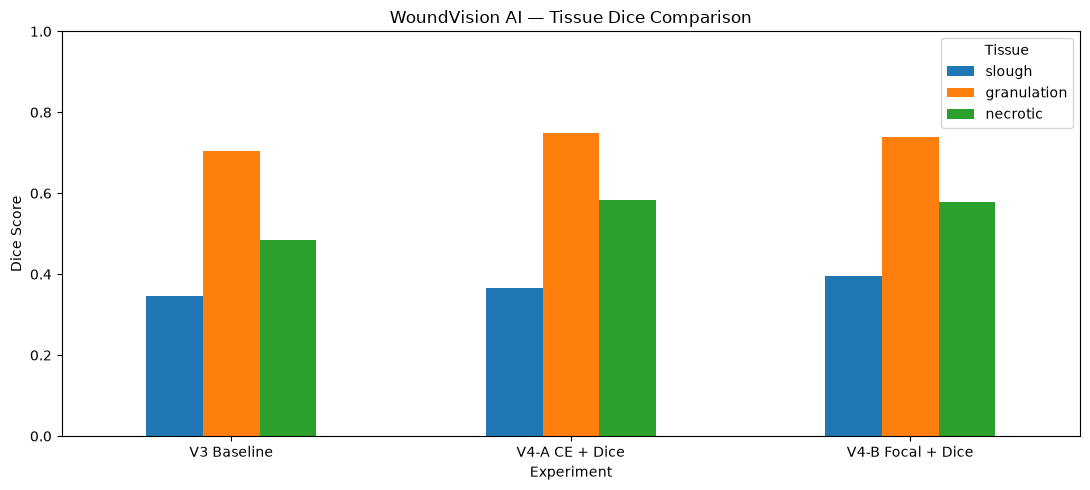

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

# Ubah hasil eksperimen menjadi DataFrame
df = pd.DataFrame(experiment_results)

# Gunakan nama model sebagai index
df = df.set_index("model")

# Buat grafik perbandingan Dice
ax = df[[
    "slough",
    "granulation",
    "necrotic"
]].plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("WoundVision AI — Tissue Dice Comparison")
ax.set_ylabel("Dice Score")
ax.set_xlabel("Experiment")
ax.set_ylim(0, 1)
ax.legend(title="Tissue")

plt.tight_layout()
plt.show()

V3 Baseline: Inference OK
V4-A CE + Dice: Inference OK
V4-B Focal + Dice: Inference OK


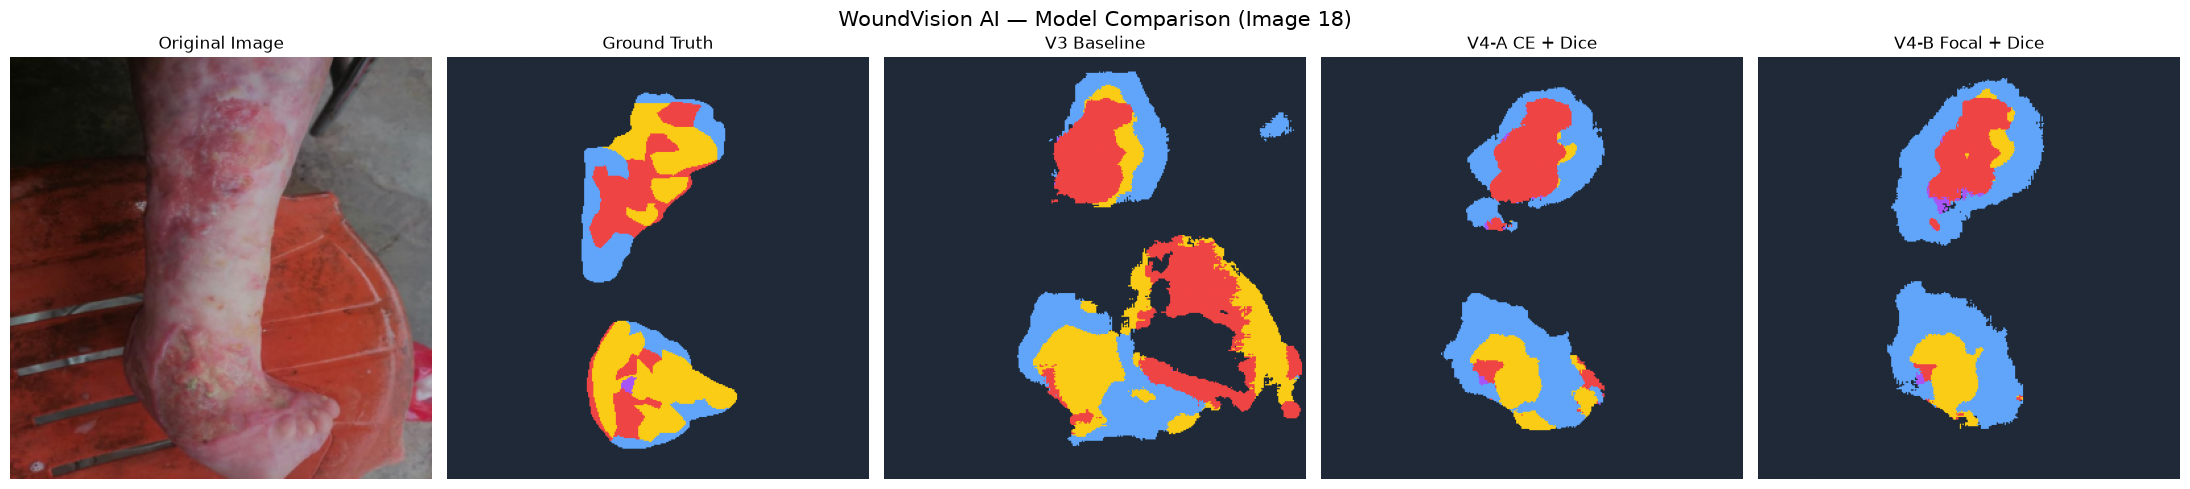

In [77]:
# Gunakan gambar validasi yang sama
sample_idx = 18

image, mask = val_dataset[sample_idx]

# Normalisasi sesuai pipeline training
x = image.unsqueeze(0).to(device)
x = (x - mean) / std

# Siapkan model untuk perbandingan
comparison_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
).to(device)

predictions = {}

# Jalankan inference untuk setiap checkpoint
for name, path in experiment_paths.items():

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    comparison_model.load_state_dict(
        ckpt["model_state"],
        strict=True
    )

    comparison_model.eval()

    with torch.inference_mode():
        logits = comparison_model(x)
        pred = logits.argmax(dim=1)

    predictions[name] = (
        pred.squeeze(0).cpu().numpy()
    )

    print(f"{name}: Inference OK")

# Visualisasi
image_np = image.permute(1, 2, 0).cpu().numpy()
mask_np = mask.cpu().numpy()

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

axes[0].imshow(image_np)
axes[0].set_title("Original Image")

axes[1].imshow(mask_np, cmap=cmap, norm=norm)
axes[1].set_title("Ground Truth")

for ax, (name, pred) in zip(
    axes[2:],
    predictions.items()
):
    ax.imshow(pred, cmap=cmap, norm=norm)
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"WoundVision AI — Model Comparison (Image {sample_idx})",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [78]:
import numpy as np
import pandas as pd

# Nama kelas yang akan dibandingkan
classes = {
    1: "Epithelial",
    2: "Slough",
    3: "Granulation",
    4: "Necrotic"
}

results = []

for model_name, pred in predictions.items():

    row = {"Model": model_name}

    for class_id, class_name in classes.items():

        gt_class = mask_np == class_id
        pred_class = pred == class_id

        intersection = np.logical_and(
            gt_class, pred_class
        ).sum()

        total = gt_class.sum() + pred_class.sum()

        dice = (
            2 * intersection / total
            if total > 0 else np.nan
        )

        row[class_name] = round(float(dice), 4)

    # Background yang salah diprediksi sebagai jaringan
    false_positive = np.logical_and(
        mask_np == 0,
        pred != 0
    ).sum()

    row["Background FP"] = int(false_positive)

    results.append(row)

# Tampilkan perbandingan
comparison_df = pd.DataFrame(results)

display(comparison_df)

,Model,Epithelial,Slough,Granulation,Necrotic,Background FP
0,V3 Baseline,0.2074,0.3640,0.2425,0.0,13440
1,V4-A CE + Dice,0.2844,0.3725,0.4133,0.0,2998
2,V4-B Focal + Dice,0.2913,0.3620,0.4058,0.0,4305


In [79]:
# === FULL VALIDATION COMPARISON ===

full_results = []

for name, path in experiment_paths.items():

    # Load checkpoint
    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    comparison_model.load_state_dict(
        ckpt["model_state"],
        strict=True
    )

    # Evaluasi seluruh 30 gambar
    cm_val = evaluate_model(
        comparison_model,
        val_loader_v4a,
        device
    )

    # Background yang salah diprediksi sebagai jaringan
    bg_fp = cm_val[0, 1:].sum().item()

    # Total piksel background sebenarnya
    bg_total = cm_val[0, :].sum().item()

    fp_rate = (
        bg_fp / bg_total * 100
        if bg_total > 0 else 0
    )

    full_results.append({
        "Model": name,
        "Background FP": bg_fp,
        "BG FP Rate (%)": round(fp_rate, 3),
        "Clinical-3 Dice": round(
            float(ckpt["clinical_3_dice"]), 4
        )
    })

# Tampilkan tabel perbandingan
full_df = pd.DataFrame(full_results)

display(full_df)

,Model,Background FP,BG FP Rate (%),Clinical-3 Dice
0,V3 Baseline,122405,4.722,0.5118
1,V4-A CE + Dice,72894,2.812,0.5668
2,V4-B Focal + Dice,111112,4.286,0.5705


In [80]:
wound_results = []

for name, path in experiment_paths.items():

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    comparison_model.load_state_dict(
        ckpt["model_state"],
        strict=True
    )

    cm = evaluate_model(
        comparison_model,
        val_loader_v4a,
        device
    ).cpu().numpy()

    # Semua kelas 1-5 dianggap foreground luka
    TP = cm[1:, 1:].sum()

    # Background salah dianggap luka
    FP = cm[0, 1:].sum()

    # Luka salah dianggap background
    FN = cm[1:, 0].sum()

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    wound_dice = 2 * TP / (2 * TP + FP + FN)

    wound_results.append({
        "Model": name,
        "Wound Precision": precision,
        "Wound Recall": recall,
        "Wound Dice": wound_dice,
        "Missed Wound Pixels": int(FN),
        "Background FP": int(FP)
    })

wound_df = pd.DataFrame(wound_results)

display(wound_df.round(4))

,Model,Wound Precision,Wound Recall,Wound Dice,Missed Wound Pixels,Background FP
0,V3 Baseline,0.7556,0.7890,0.7719,101199,122405
1,V4-A CE + Dice,0.8368,0.7796,0.8072,105683,72894
2,V4-B Focal + Dice,0.7841,0.8413,0.8117,76083,111112


In [81]:
import inspect

# Lihat implementasi pembacaan gambar dan mask
source = inspect.getsource(WoundDataset.__getitem__)

lines = source.splitlines()

print("=== DATASET GETITEM ===")

for i, line in enumerate(lines[:35], start=1):
    print(f"{i:02d}: {line}")

print("\nTotal lines:", len(lines))

=== DATASET GETITEM ===
01:     def __getitem__(self, index):
02:         image_path, mask_path = self.samples[index]
03: 
04:         # Baca gambar RGB
05:         with Image.open(image_path) as img:
06:             image = img.convert("RGB").resize(
07:                 (self.image_size, self.image_size),
08:                 Image.Resampling.BILINEAR
09:             )
10: 
11:          # Baca indexed segmentation mask
12:         with Image.open(mask_path) as mask:
13:             mask = mask.resize(
14:                 (self.image_size, self.image_size),
15:                 Image.Resampling.NEAREST
16:                 )
17: 
18:             mask_array = np.array(
19:                 mask, dtype=np.int64
20:             )
21: 
22:             # Konversi menjadi tensor
23:             image_array = np.array(image).copy()
24: 
25:             image_tensor = (
26:                 torch.from_numpy(image_array)
27:                 .permute(2, 0, 1)
28:                 .float() / 255.0
29: 